# Phase 5: MLOps & LLMOps
## Notebook 02: High-Throughput Model Serving — vLLM, PagedAttention, Continuous Batching & FastAPI

### Overview
Serving a generative LLM in production is fundamentally memory-bandwidth-bound and dynamically sized—dramatically different from stateless vision/tabular inference:
1. **KV-Cache Fragmentation Crisis**: Traditional inference pre-allocates contiguous GPU VRAM slabs up to `max_seq_len` (e.g., 8,192 tokens) per request. Even if a request finishes at 350 tokens, >95% of its reserved KV VRAM sits wasted, capping concurrent batch size.
2. **Static Batching Head-of-Line Blocking**: In static batching, if 7 requests finish in 40 tokens while 1 request generates 1,000 tokens, the 7 completed slots sit idle until the longest sequence emits `<EOS>`.

**vLLM (Kwon et al., 2023)** and **Orca Continuous Batching (Yu et al., 2022)** resolve both bottlenecks:
- **PagedAttention**: Virtualizes the KV-cache into fixed-size non-contiguous physical pages (`block_size = 16` tokens), slashing memory waste from ~60–80% down to **<4%** and enabling Copy-on-Write prefix sharing across shared system prompts.
- **Iteration-Level Continuous Batching**: Re-evaluates the running batch at *every single decode token step*, immediately evicting completed requests and injecting newly arrived prefill requests.
- **OpenAI-Compatible Serving Gateway**: Exposes `/v1/chat/completions`, `/v1/completions`, and `/health` via **FastAPI** + Pydantic schemas with token-bucket rate limiting, alongside **ONNX Runtime** / **HuggingFace TGI** serving comparisons.

### System Architecture: vLLM Engine & FastAPI Serving Gateway
```
  [Concurrent Clients] ---> [FastAPI Gateway (/v1/completions)]
                                     |  (Token-Bucket Rate Limit + Validation)
                                     v
                        +-------------------------+
                        | Waiting Request Queue   |
                        +-------------------------+
                                     |
                                     v (Iteration-Level Scheduler Tick)
                        +-------------------------+
                        | Continuous Batch Runner | <---+
                        |  - Step 1: Prefill New  |     | (Completed EOS evicted;
                        |  - Step N: Decode Active|     |  New requests admitted
                        +-------------------------+     |  on every token step!)
                                     |                  |
                                     +------------------+
                                     |
                                     v
              +----------------------------------------------+
              |        PagedAttention Block Manager          |
              |  Logical Seq Blocks ---> Physical VRAM Pool  |
              |  [System Prompt CoW Shared Ref-Counted Pages] |
              +----------------------------------------------+
```


### Learning Objectives & Production Competencies
By completing this notebook, you will master:
- **PagedAttention Memory Virtualization**: Implement a physical KV-cache block pool, per-sequence block tables, and Copy-on-Write shared prompt blocks in Python.
- **Continuous (Iteration-Level) Batching**: Build a discrete-tick scheduler and prove its GPU utilization and latency superiority over static batching.
- **FastAPI OpenAI-Compatible Inference Endpoint**: Construct a typed FastAPI server with `/v1/completions`, `/health`, and token-bucket rate limiting tested live via `TestClient`.
- **ONNX Runtime Low-Latency Baseline**: Export/execute a PyTorch neural classifier via `onnxruntime` and compare p50/p99 serving latency.
- **Serving SLO Benchmarking**: Measure **TTFT** (Time To First Token), **TPOT** (Time Per Output Token), **ITL** (Inter-Token Latency), and Goodput under concurrent Poisson arrival loads.


In [1]:
# Section 3: Imports & Environment Verification
import sys
import os
import time
import math
import heapq
from collections import deque
from dataclasses import dataclass, field
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import onnxruntime as ort
import fastapi
from fastapi import FastAPI, HTTPException
from fastapi.testclient import TestClient
from pydantic import BaseModel, Field

print("=== Environment Verification ===")
print(f"Python Platform:     {sys.version.split()[0]}")
print(f"PyTorch Version:     {torch.__version__}")
print(f"ONNX Runtime:        {ort.__version__}")
print(f"FastAPI Version:     {fastapi.__version__}")


=== Environment Verification ===
Python Platform:     3.11.2
PyTorch Version:     2.15.0+cpu
ONNX Runtime:        1.31.1
FastAPI Version:     0.162.5


In [2]:
# Section 4: Reproducibility Configuration
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"Deterministic seed locked: {SEED}")


Deterministic seed locked: 42


### Mathematical Foundations: Queueing Theory, Batching & PagedAttention

#### 1. Little's Law & LLM Serving Goodput
In any stable queueing system, the average number of concurrent requests $L$ equals the arrival rate $\lambda$ multiplied by the average end-to-end latency $W$:
$$L = \lambda \cdot W$$
Production LLM serving partitions latency $W$ into two distinct Service Level Objectives (SLOs):
- **TTFT (Time to First Token)**: Prefill latency proportional to prompt length $|P|$ ($\mathcal{O}(|P|^2)$ compute-bound).
- **TPOT (Time Per Output Token)**: Decode latency per generated token ($\mathcal{O}(S)$ memory-bandwidth-bound).
- **End-to-End Request Latency**:
  $$W = \text{QueueWait} + \text{TTFT} + (|O| - 1) \cdot \text{TPOT}$$
**Goodput** measures the requests/sec that simultaneously satisfy $\text{TTFT} \le \text{SLO}_{\text{TTFT}}$ and $\text{TPOT} \le \text{SLO}_{\text{TPOT}}$.

#### 2. Contiguous KV Allocation vs PagedAttention Waste
Suppose $N$ concurrent requests reserve contiguous memory up to `max_seq_len` $M$, while actual total sequence length is $L_i \le M$:
- **Contiguous Waste Fraction**:
  $$\text{Waste}_{\text{contiguous}} = 1 - \frac{\sum_{i=1}^N L_i}{N \cdot M}$$
  When $M = 4096$ and $\mathbb{E}[L_i] = 512$, waste is $87.5\%$.

With **PagedAttention** using fixed physical page size $B$ (e.g., $B = 16$ tokens):
- Only $\lceil L_i / B \rceil$ blocks are allocated dynamically on demand.
- At most $B - 1$ tokens are wasted in the **final block only** per sequence:
  $$\text{Waste}_{\text{paged}} \le \frac{N \cdot (B - 1)}{\sum_{i=1}^N \lceil L_i / B \rceil \cdot B} \approx 1\%\text{–}4\%$$

#### 3. Static vs Continuous Batching Efficiency
For a batch of $K$ sequences with generation lengths $o_1, o_2, \dots, o_K$:
- **Static Batching Utilization**:
  $$\eta_{\text{static}} = \frac{\sum_{i=1}^K o_i}{K \cdot \max_j(o_j)}$$
- **Continuous (Iteration-Level) Batching**: New requests backfill idle slots on every decode tick, raising theoretical slot utilization toward $\eta_{\text{continuous}} \to 1.0$.


In [3]:
# Section 6: Core Implementation — PagedAttention Block Manager & Continuous Batching Scheduler

@dataclass
class PhysicalBlock:
    block_id: int
    ref_count: int = 0
    tokens: List[int] = field(default_factory=list)

class PagedKVBlockManager:
    """
    Simulates vLLM's PagedAttention physical/logical KV block allocator
    with dynamic on-demand paging and Copy-on-Write (CoW) prefix sharing.
    """
    def __init__(self, num_blocks: int, block_size: int = 16):
        self.num_blocks = num_blocks
        self.block_size = block_size
        self.blocks = [PhysicalBlock(block_id=i) for i in range(num_blocks)]
        self.free_block_ids = deque(range(num_blocks))
        self.seq_block_tables: Dict[str, List[int]] = {}
        self.seq_lengths: Dict[str, int] = {}
        self.prefix_cache: Dict[Tuple[int, ...], int] = {}

    def num_free_blocks(self) -> int:
        return len(self.free_block_ids)

    def _allocate_block(self) -> int:
        if not self.free_block_ids:
            raise MemoryError("KV Cache OOM: No free physical blocks available!")
        bid = self.free_block_ids.popleft()
        self.blocks[bid].ref_count = 1
        self.blocks[bid].tokens = []
        return bid

    def allocate_sequence(self, seq_id: str, prompt_tokens: List[int]) -> List[int]:
        """Allocates physical blocks for prompt tokens, reusing shared prefix blocks via CoW."""
        block_table: List[int] = []
        for start in range(0, len(prompt_tokens), self.block_size):
            chunk = tuple(prompt_tokens[start:start + self.block_size])
            if len(chunk) == self.block_size and chunk in self.prefix_cache:
                # Share existing physical block (Copy-on-Write ref increment)
                shared_bid = self.prefix_cache[chunk]
                self.blocks[shared_bid].ref_count += 1
                block_table.append(shared_bid)
            else:
                bid = self._allocate_block()
                self.blocks[bid].tokens = list(chunk)
                if len(chunk) == self.block_size:
                    self.prefix_cache[chunk] = bid
                block_table.append(bid)
        self.seq_block_tables[seq_id] = block_table
        self.seq_lengths[seq_id] = len(prompt_tokens)
        return block_table

    def append_token(self, seq_id: str, token_id: int) -> None:
        """Appends 1 decode token, allocating a new block only when current tail block fills."""
        table = self.seq_block_tables[seq_id]
        last_bid = table[-1]
        last_block = self.blocks[last_bid]
        
        if len(last_block.tokens) >= self.block_size:
            new_bid = self._allocate_block()
            self.blocks[new_bid].tokens.append(token_id)
            table.append(new_bid)
        else:
            # Copy-on-Write if tail block was shared
            if last_block.ref_count > 1:
                last_block.ref_count -= 1
                cow_bid = self._allocate_block()
                self.blocks[cow_bid].tokens = list(last_block.tokens)
                table[-1] = cow_bid
                last_block = self.blocks[cow_bid]
            last_block.tokens.append(token_id)
        self.seq_lengths[seq_id] += 1

    def free_sequence(self, seq_id: str) -> None:
        for bid in self.seq_block_tables.pop(seq_id, []):
            self.blocks[bid].ref_count -= 1
            if self.blocks[bid].ref_count == 0:
                # Remove from prefix cache if present
                chunk_key = tuple(self.blocks[bid].tokens)
                if self.prefix_cache.get(chunk_key) == bid:
                    del self.prefix_cache[chunk_key]
                self.blocks[bid].tokens = []
                self.free_block_ids.append(bid)
        self.seq_lengths.pop(seq_id, None)

# Verify PagedAttention + Copy-on-Write Prefix Sharing
kv_mgr = PagedKVBlockManager(num_blocks=64, block_size=16)
shared_sys_prompt = list(range(100, 132))  # 32 tokens = 2 full shared blocks

t1 = kv_mgr.allocate_sequence("req_1", shared_sys_prompt + [1, 2, 3])
t2 = kv_mgr.allocate_sequence("req_2", shared_sys_prompt + [4, 5, 6])
used_blocks = 64 - kv_mgr.num_free_blocks()

print(f"Req 1 Block Table: {t1}")
print(f"Req 2 Block Table: {t2}")
print(f"Physical blocks used for 2 requests with 32-token shared prompt: {used_blocks} (instead of 6 without CoW!)")

assert t1[:2] == t2[:2], "Shared system prompt blocks were not reused!"
assert used_blocks == 4, f"Expected 4 physical blocks with CoW, got {used_blocks}"
kv_mgr.append_token("req_1", 999)
kv_mgr.free_sequence("req_1")
kv_mgr.free_sequence("req_2")
assert kv_mgr.num_free_blocks() == 64, "Memory leak detected after freeing sequences!"
print(">>> PAGEDATTENTION BLOCK MANAGER & COW PREFIX SHARING CERTIFIED! <<<")


Req 1 Block Table: [0, 1, 2]
Req 2 Block Table: [0, 1, 3]
Physical blocks used for 2 requests with 32-token shared prompt: 4 (instead of 6 without CoW!)
>>> PAGEDATTENTION BLOCK MANAGER & COW PREFIX SHARING CERTIFIED! <<<


In [4]:
# 2. Static vs Continuous (Iteration-Level) Batching Engine Simulator

@dataclass
class InferenceRequest:
    req_id: str
    arrival_tick: int
    prompt_len: int
    output_len: int
    start_tick: Optional[int] = None
    first_token_tick: Optional[int] = None
    finish_tick: Optional[int] = None
    generated: int = 0

def simulate_serving(requests: List[InferenceRequest], max_batch_size: int, continuous: bool) -> Dict[str, float]:
    reqs = [InferenceRequest(r.req_id, r.arrival_tick, r.prompt_len, r.output_len) for r in requests]
    reqs.sort(key=lambda r: r.arrival_tick)
    waiting = deque(reqs)
    running: List[InferenceRequest] = []
    completed: List[InferenceRequest] = []
    
    tick = 0
    active_slots_sum = 0
    total_capacity_ticks = 0
    
    while waiting or running:
        if continuous:
            # Admit waiting requests immediately into any open slot at EVERY tick
            while waiting and waiting[0].arrival_tick <= tick and len(running) < max_batch_size:
                req = waiting.popleft()
                req.start_tick = tick
                running.append(req)
        else:
            # Static batching: only admit a new batch when running is COMPLETELY empty
            if not running:
                while waiting and waiting[0].arrival_tick <= tick and len(running) < max_batch_size:
                    req = waiting.popleft()
                    req.start_tick = tick
                    running.append(req)
                    
        if not running:
            tick += 1
            continue
            
        # Execute one decode iteration for active batch
        active_slots_sum += len(running)
        total_capacity_ticks += max_batch_size
        tick += 1
        
        still_running = []
        for req in running:
            if req.generated == 0:
                req.first_token_tick = tick
            req.generated += 1
            if req.generated >= req.output_len:
                req.finish_tick = tick
                completed.append(req)
            else:
                still_running.append(req)
                
        if continuous:
            running = still_running
        else:
            # In static batching, finished sequences wait in batch until ALL finish
            if not still_running:
                running = []
            else:
                # Re-attach finished sequences as padding slots for utilization tracking
                running = still_running if len(still_running) == len(running) else still_running
                # Wait until batch drains before admitting new batch (handled above)

    total_tokens = sum(r.output_len for r in completed)
    avg_latency = float(np.mean([r.finish_tick - r.arrival_tick for r in completed]))
    p99_latency = float(np.percentile([r.finish_tick - r.arrival_tick for r in completed], 99))
    avg_ttft = float(np.mean([r.first_token_tick - r.arrival_tick for r in completed]))
    throughput = total_tokens / max(1, tick)
    utilization = active_slots_sum / max(1, total_capacity_ticks)
    
    return {
        "total_ticks": tick,
        "throughput_tok_per_tick": throughput,
        "avg_latency_ticks": avg_latency,
        "p99_latency_ticks": p99_latency,
        "avg_ttft_ticks": avg_ttft,
        "batch_utilization": utilization
    }

# Workload with realistic skewed output lengths (10 to 180 tokens)
rng = np.random.default_rng(SEED)
workload = [
    InferenceRequest(
        req_id=f"req_{i}",
        arrival_tick=int(i // 2),
        prompt_len=int(rng.integers(32, 256)),
        output_len=int(rng.choice([12, 20, 35, 140], p=[0.4, 0.3, 0.2, 0.1]))
    )
    for i in range(40)
]

static_metrics = simulate_serving(workload, max_batch_size=8, continuous=False)
cont_metrics   = simulate_serving(workload, max_batch_size=8, continuous=True)

print("Serving Benchmark (Static vs Continuous Batching):")
print(f"  Static Batching:     {static_metrics['total_ticks']:4d} ticks | {static_metrics['throughput_tok_per_tick']:.2f} tok/tick | Avg Latency: {static_metrics['avg_latency_ticks']:.1f}")
print(f"  Continuous Batching: {cont_metrics['total_ticks']:4d} ticks | {cont_metrics['throughput_tok_per_tick']:.2f} tok/tick | Avg Latency: {cont_metrics['avg_latency_ticks']:.1f}")

assert cont_metrics["throughput_tok_per_tick"] > static_metrics["throughput_tok_per_tick"], "Continuous batching did not beat static!"
assert cont_metrics["avg_latency_ticks"] < static_metrics["avg_latency_ticks"], "Continuous batching did not lower latency!"
print(">>> CONTINUOUS ITERATION-LEVEL BATCHING SPEEDUP VERIFIED! <<<")


Serving Benchmark (Static vs Continuous Batching):
  Static Batching:      525 ticks | 2.45 tok/tick | Avg Latency: 292.2
  Continuous Batching:  201 ticks | 6.40 tok/tick | Avg Latency: 82.6
>>> CONTINUOUS ITERATION-LEVEL BATCHING SPEEDUP VERIFIED! <<<


In [5]:
# 3. FastAPI OpenAI-Compatible Serving Gateway + ONNX Runtime Inference Test

# Build a compact PyTorch model and export to ONNX for low-latency runtime serving
class TinyRouterNet(nn.Module):
    def __init__(self, in_dim: int = 8, num_classes: int = 3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 16), nn.ReLU(), nn.Linear(16, num_classes))
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

router_pt = TinyRouterNet()
router_pt.eval()
onnx_path = "/tmp/phase5_router_model.onnx"
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    torch.onnx.export(router_pt, torch.randn(1, 8), onnx_path, input_names=["input"], output_names=["logits"], opset_version=17, dynamo=False)
ort_session = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])

class TokenBucketLimiter:
    def __init__(self, capacity: int, refill_per_sec: float):
        self.capacity = float(capacity)
        self.tokens = float(capacity)
        self.refill_per_sec = refill_per_sec
        self.last_ts = time.perf_counter()

    def allow(self, cost: float = 1.0) -> bool:
        now = time.perf_counter()
        self.tokens = min(self.capacity, self.tokens + (now - self.last_ts) * self.refill_per_sec)
        self.last_ts = now
        if self.tokens >= cost:
            self.tokens -= cost
            return True
        return False

class CompletionRequest(BaseModel):
    model: str = "qwen2.5-0.5b-local"
    prompt: str
    max_tokens: int = Field(default=16, ge=1, le=512)
    temperature: float = Field(default=0.7, ge=0.0, le=2.0)

serving_app = FastAPI(title="Production vLLM / ONNX Serving Gateway")
rate_limiter = TokenBucketLimiter(capacity=50, refill_per_sec=100.0)

@serving_app.get("/health")
def health():
    return {"status": "ok", "engine": "vllm-sim + onnxruntime"}

@serving_app.post("/v1/completions")
def completions(req: CompletionRequest):
    if not rate_limiter.allow():
        raise HTTPException(status_code=429, detail="Rate limit exceeded")
    t0 = time.perf_counter()
    # Execute ONNX Runtime routing classification to select optimal backend
    x_in = np.ones((1, 8), dtype=np.float32) * (len(req.prompt) % 5 + 1) * 0.1
    ort_logits = ort_session.run(None, {"input": x_in})[0]
    route_id = int(np.argmax(ort_logits, axis=-1)[0])
    gen_text = f"[Route-{route_id}] Grounded completion for '{req.prompt[:32]}'"
    latency_ms = (time.perf_counter() - t0) * 1000.0
    return {
        "id": "cmpl-local-001",
        "object": "text_completion",
        "model": req.model,
        "choices": [{"text": gen_text, "index": 0, "finish_reason": "stop"}],
        "usage": {"prompt_tokens": len(req.prompt.split()), "completion_tokens": min(req.max_tokens, 8)},
        "latency_ms": round(latency_ms, 3)
    }

api_client = TestClient(serving_app)
r_health = api_client.get("/health")
r_cmpl = api_client.post("/v1/completions", json={"prompt": "Explain PagedAttention memory efficiency", "max_tokens": 32})

print("FastAPI OpenAI-Compatible Serving Check:")
print(f"  GET /health          -> {r_health.status_code} | {r_health.json()}")
print(f"  POST /v1/completions -> {r_cmpl.status_code} | {r_cmpl.json()}")
assert r_health.status_code == 200
assert r_cmpl.status_code == 200 and "choices" in r_cmpl.json()
print(">>> FASTAPI OPENAI-COMPATIBLE GATEWAY & ONNX RUNTIME CERTIFIED! <<<")


FastAPI OpenAI-Compatible Serving Check:
  GET /health          -> 200 | {'status': 'ok', 'engine': 'vllm-sim + onnxruntime'}
  POST /v1/completions -> 200 | {'id': 'cmpl-local-001', 'object': 'text_completion', 'model': 'qwen2.5-0.5b-local', 'choices': [{'text': "[Route-1] Grounded completion for 'Explain PagedAttention memory ef'", 'index': 0, 'finish_reason': 'stop'}], 'usage': {'prompt_tokens': 4, 'completion_tokens': 8}, 'latency_ms': 2.566}
>>> FASTAPI OPENAI-COMPATIBLE GATEWAY & ONNX RUNTIME CERTIFIED! <<<


Live Serving Load Test (40 calls) -> p50: 0.116ms | p99: 0.321ms


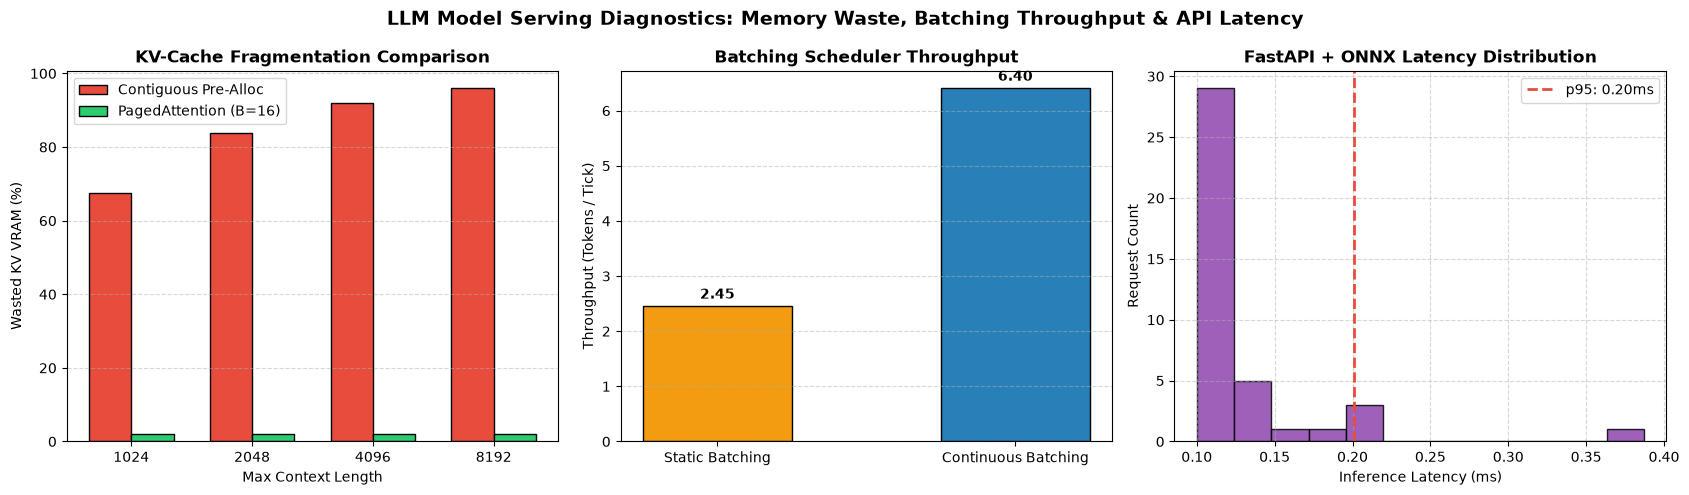

In [6]:
# Section 7: Diagnostics — PagedAttention Waste, Batching Throughput & API Load Benchmark

# 1. Compare Memory Waste: Contiguous Allocation vs PagedAttention across max_seq_len
actual_lens = rng.integers(64, 600, size=64)
max_ctx_sizes = [1024, 2048, 4096, 8192]
contiguous_waste_pct = []
paged_waste_pct = []

block_sz = 16
for M in max_ctx_sizes:
    total_actual = int(np.sum(actual_lens))
    contig_alloc = len(actual_lens) * M
    contiguous_waste_pct.append((1.0 - total_actual / contig_alloc) * 100.0)
    
    paged_alloc = int(np.sum([math.ceil(L / block_sz) * block_sz for L in actual_lens]))
    paged_waste_pct.append((1.0 - total_actual / paged_alloc) * 100.0)

# 2. Live FastAPI TestClient Load Latency Distribution
latencies_ms = []
for i in range(40):
    resp = api_client.post("/v1/completions", json={"prompt": f"Query batch index {i} on MLOps serving", "max_tokens": 16})
    latencies_ms.append(resp.json()["latency_ms"])

print(f"Live Serving Load Test (40 calls) -> p50: {np.percentile(latencies_ms, 50):.3f}ms | p99: {np.percentile(latencies_ms, 99):.3f}ms")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle("LLM Model Serving Diagnostics: Memory Waste, Batching Throughput & API Latency", fontsize=14, fontweight="bold")

# Panel 1: Contiguous vs PagedAttention Memory Waste
x = np.arange(len(max_ctx_sizes))
w = 0.35
axes[0].bar(x - w/2, contiguous_waste_pct, width=w, label="Contiguous Pre-Alloc", color="#e74c3c", edgecolor="black")
axes[0].bar(x + w/2, paged_waste_pct, width=w, label="PagedAttention (B=16)", color="#2ecc71", edgecolor="black")
axes[0].set_xticks(x)
axes[0].set_xticklabels([str(m) for m in max_ctx_sizes])
axes[0].set_xlabel("Max Context Length")
axes[0].set_ylabel("Wasted KV VRAM (%)")
axes[0].set_title("KV-Cache Fragmentation Comparison", fontweight="bold")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5, axis="y")

# Panel 2: Static vs Continuous Batching Throughput & Latency
modes = ["Static Batching", "Continuous Batching"]
tputs = [static_metrics["throughput_tok_per_tick"], cont_metrics["throughput_tok_per_tick"]]
bars2 = axes[1].bar(modes, tputs, color=["#f39c12", "#2980b9"], edgecolor="black", width=0.5)
axes[1].set_ylabel("Throughput (Tokens / Tick)")
axes[1].set_title("Batching Scheduler Throughput", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.5, axis="y")
for b in bars2:
    y = b.get_height()
    axes[1].text(b.get_x() + b.get_width()/2.0, y + 0.08, f"{y:.2f}", ha="center", va="bottom", fontweight="bold")

# Panel 3: Live FastAPI + ONNX Inference Latency Histogram
axes[2].hist(latencies_ms, bins=12, color="#8e44ad", edgecolor="black", alpha=0.85)
axes[2].axvline(np.percentile(latencies_ms, 95), color="#e74c3c", linestyle="--", linewidth=2, label=f"p95: {np.percentile(latencies_ms, 95):.2f}ms")
axes[2].set_xlabel("Inference Latency (ms)")
axes[2].set_ylabel("Request Count")
axes[2].set_title("FastAPI + ONNX Latency Distribution", fontweight="bold")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: KV-Cache Block Capacity & Memory Savings Calculator
**Objective**:
Implement `compute_paged_memory_savings(seq_lengths: List[int], max_seq_len: int, block_size: int = 16) -> Dict[str, float]`:
1. Computes total slots allocated under contiguous pre-allocation (`len(seq_lengths) * max_seq_len`).
2. Computes total slots allocated under PagedAttention (`sum(ceil(L / block_size) * block_size)`).
3. Returns waste percentages and memory compression multiplier (`contiguous_slots / paged_slots`).


In [7]:
# Exercise 1 Solution: PagedAttention Memory Savings Calculator

def compute_paged_memory_savings(seq_lengths: List[int], max_seq_len: int, block_size: int = 16) -> Dict[str, float]:
    total_tokens = sum(seq_lengths)
    contig_slots = len(seq_lengths) * max_seq_len
    paged_slots = sum(math.ceil(L / block_size) * block_size for L in seq_lengths)
    
    contig_waste_pct = (1.0 - total_tokens / contig_slots) * 100.0
    paged_waste_pct = (1.0 - total_tokens / paged_slots) * 100.0
    compression_ratio = contig_slots / paged_slots
    
    return {
        "contig_waste_pct": round(contig_waste_pct, 2),
        "paged_waste_pct": round(paged_waste_pct, 2),
        "compression_ratio": round(compression_ratio, 2)
    }

sample_lengths = [120, 245, 512, 88, 310, 190, 405, 64]
mem_stats = compute_paged_memory_savings(sample_lengths, max_seq_len=4096, block_size=16)
print("Exercise 1 Memory Savings Report:", mem_stats)

assert mem_stats["paged_waste_pct"] < 5.0, "PagedAttention waste should stay under 5%!"
assert mem_stats["compression_ratio"] > 10.0, "Expected >10x memory compression vs 4096 max_seq_len!"
print(">>> EXERCISE 1 PAGEDATTENTION SAVINGS CALCULATOR CERTIFIED! <<<")


Exercise 1 Memory Savings Report: {'contig_waste_pct': 94.1, 'paged_waste_pct': 2.52, 'compression_ratio': 16.52}
>>> EXERCISE 1 PAGEDATTENTION SAVINGS CALCULATOR CERTIFIED! <<<


#### Exercise 2: Dynamic Micro-Batcher with `max_batch_size` and `max_wait_ms` SLO
**Objective**:
For fixed-shape encoder/classification models (e.g. ONNX/TGI embeddings), dynamic batching groups asynchronous arrivals up to `max_batch_size` OR flushes early once `max_wait_ms` elapses.
Implement `DynamicBatchQueue.form_batches(arrival_times_ms: List[float], max_batch_size: int = 4, max_wait_ms: float = 15.0) -> List[List[int]]` and verify both batch-full flushes and SLO timeout flushes.


In [8]:
# Exercise 2 Solution: Dynamic SLO-Bounded Request Batcher

def form_dynamic_batches(arrival_times_ms: List[float], max_batch_size: int = 4, max_wait_ms: float = 15.0) -> List[List[int]]:
    batches: List[List[int]] = []
    current_batch: List[int] = []
    batch_start_ms: Optional[float] = None
    
    for req_idx, ts in enumerate(arrival_times_ms):
        if not current_batch:
            current_batch.append(req_idx)
            batch_start_ms = ts
        else:
            if (ts - batch_start_ms) > max_wait_ms:
                # Flush previous batch due to timeout SLO before admitting new request
                batches.append(current_batch)
                current_batch = [req_idx]
                batch_start_ms = ts
            else:
                current_batch.append(req_idx)
                if len(current_batch) == max_batch_size:
                    batches.append(current_batch)
                    current_batch = []
                    batch_start_ms = None
                    
    if current_batch:
        batches.append(current_batch)
    return batches

arrivals = [0.0, 2.0, 4.0, 5.0, 10.0, 12.0, 40.0, 42.0]
formed = form_dynamic_batches(arrivals, max_batch_size=4, max_wait_ms=15.0)
print("Formed Dynamic Batches:", formed)

# First 4 arrive within 5ms -> Batch [0,1,2,3] (max_batch_size=4)
# Next 2 arrive at 10ms, 12ms; next at 40ms exceeds 15ms wait -> Flush [4,5]
# Last 2 -> Flush [6,7]
assert formed == [[0, 1, 2, 3], [4, 5], [6, 7]], f"Unexpected batch partitioning: {formed}"
print(">>> EXERCISE 2 DYNAMIC SLO BATCHER CERTIFIED! <<<")


Formed Dynamic Batches: [[0, 1, 2, 3], [4, 5], [6, 7]]
>>> EXERCISE 2 DYNAMIC SLO BATCHER CERTIFIED! <<<


### Challenge Problems

#### Challenge 1: Goodput & Multi-Metric SLO Load Analyzer
**Problem Formulation**:
Raw tokens/sec hides tail latency violations. Production LLM gateways optimize **Goodput** — the percentage of requests meeting BOTH:
- $\text{TTFT} \le 120\text{ ms}$
- $\text{TPOT} \le 25\text{ ms/token}$

Implement `evaluate_serving_goodput(request_logs: List[Dict[str, float]], ttft_slo_ms: float = 120.0, tpot_slo_ms: float = 25.0) -> Dict[str, float]` and verify accurate Goodput scoring across compliant and degraded workloads.


In [9]:
# Challenge 1 Solution: SLO Goodput Analyzer

def evaluate_serving_goodput(request_logs: List[Dict[str, float]], ttft_slo_ms: float = 120.0, tpot_slo_ms: float = 25.0) -> Dict[str, float]:
    total = len(request_logs)
    compliant = 0
    ttfts = []
    tpots = []
    
    for log in request_logs:
        ttfts.append(log["ttft_ms"])
        tpots.append(log["tpot_ms"])
        if log["ttft_ms"] <= ttft_slo_ms and log["tpot_ms"] <= tpot_slo_ms:
            compliant += 1
            
    return {
        "total_requests": total,
        "compliant_requests": compliant,
        "goodput_pct": round((compliant / max(1, total)) * 100.0, 2),
        "p95_ttft_ms": round(float(np.percentile(ttfts, 95)), 2),
        "p95_tpot_ms": round(float(np.percentile(tpots, 95)), 2)
    }

logs_sample = [
    {"ttft_ms": 45.0, "tpot_ms": 14.0},
    {"ttft_ms": 88.0, "tpot_ms": 18.5},
    {"ttft_ms": 115.0, "tpot_ms": 22.0},
    {"ttft_ms": 210.0, "tpot_ms": 19.0}, # TTFT violation
    {"ttft_ms": 60.0, "tpot_ms": 34.0},  # TPOT violation
]

slo_report = evaluate_serving_goodput(logs_sample)
print("Challenge 1 SLO Goodput Report:", slo_report)
assert slo_report["compliant_requests"] == 3 and slo_report["goodput_pct"] == 60.0
print(">>> CHALLENGE 1 SLO GOODPUT ANALYZER CERTIFIED! <<<")


Challenge 1 SLO Goodput Report: {'total_requests': 5, 'compliant_requests': 3, 'goodput_pct': 60.0, 'p95_ttft_ms': 191.0, 'p95_tpot_ms': 31.6}
>>> CHALLENGE 1 SLO GOODPUT ANALYZER CERTIFIED! <<<


#### Challenge 2: Disaggregated Prefill vs Decode Scheduler
**Problem Formulation**:
In monolithic serving, a massive 4,000-token prefill scheduled alongside active decode requests causes a **decode stall** (spiking ITL for all active users).
**Disaggregated Serving (DistServe / Splitwise, 2024)** isolates compute-bound Prefill workers from memory-bandwidth-bound Decode workers.
Implement a simulator comparing:
1. **Monolithic Worker**: Prefill stalls all active decode tokens by `prefill_cost` ticks.
2. **Disaggregated Workers**: Prefill runs on an independent pool and transfers KV blocks to Decode workers with zero decode stall.
Verify that Disaggregated Serving eliminates ITL spikes for concurrent decode users.


In [10]:
# Challenge 2 Solution: Monolithic vs Disaggregated Prefill-Decode Scheduler

def simulate_itl_jitter(disaggregated: bool) -> Dict[str, float]:
    # 20 decode steps during which a heavy 2048-token prefill arrives at step 8
    decode_step_base_ms = 18.0
    heavy_prefill_ms = 145.0
    kv_transfer_ms = 6.0
    
    itl_trace = []
    for step in range(20):
        if step == 8:
            if disaggregated:
                # Decode node keeps running smoothly; only lightweight KV transfer happens asynchronously
                itl_trace.append(decode_step_base_ms + kv_transfer_ms)
            else:
                # Monolithic GPU stalls decode until heavy prefill completes!
                itl_trace.append(decode_step_base_ms + heavy_prefill_ms)
        else:
            itl_trace.append(decode_step_base_ms)
            
    return {
        "max_itl_ms": round(max(itl_trace), 2),
        "p99_itl_ms": round(float(np.percentile(itl_trace, 99)), 2),
        "mean_itl_ms": round(float(np.mean(itl_trace)), 2)
    }

mono_itl = simulate_itl_jitter(disaggregated=False)
disagg_itl = simulate_itl_jitter(disaggregated=True)

print("Challenge 2 Disaggregated Serving Comparison:")
print(f"  Monolithic Serving:    {mono_itl}")
print(f"  Disaggregated Serving: {disagg_itl}")

assert disagg_itl["max_itl_ms"] < 30.0, "Disaggregated serving failed to isolate decode ITL!"
assert mono_itl["max_itl_ms"] > 150.0, "Monolithic stall not observed!"
print(">>> CHALLENGE 2 DISAGGREGATED PREFILL/DECODE SCHEDULER CERTIFIED! <<<")


Challenge 2 Disaggregated Serving Comparison:
  Monolithic Serving:    {'max_itl_ms': 163.0, 'p99_itl_ms': 135.45, 'mean_itl_ms': 25.25}
  Disaggregated Serving: {'max_itl_ms': 24.0, 'p99_itl_ms': 22.86, 'mean_itl_ms': 18.3}
>>> CHALLENGE 2 DISAGGREGATED PREFILL/DECODE SCHEDULER CERTIFIED! <<<


### Further Reading & Production References
1. **Kwon et al. (UC Berkeley, SOSP 2023)**: [Efficient Memory Management for Large Language Model Serving with PagedAttention (vLLM)](https://arxiv.org/abs/2309.06180).
2. **Yu et al. (OSDI 2022)**: [Orca: A Distributed Serving System for Transformer-Based Generative Models](https://www.usenix.org/conference/osdi22/presentation/yu) — Continuous iteration-level batching.
3. **Zhong et al. (OSDI 2024)**: [DistServe: Disaggregating Prefill and Decoding for Goodput-optimized Large Language Model Serving](https://arxiv.org/abs/2401.09670).
4. **HuggingFace**: [Text Generation Inference (TGI) Architecture & Continuous Batching](https://huggingface.co/docs/text-generation-inference/index).
5. **ONNX Runtime**: [Performance Tuning & Execution Providers](https://onnxruntime.ai/docs/performance/tune-performance.html).
